
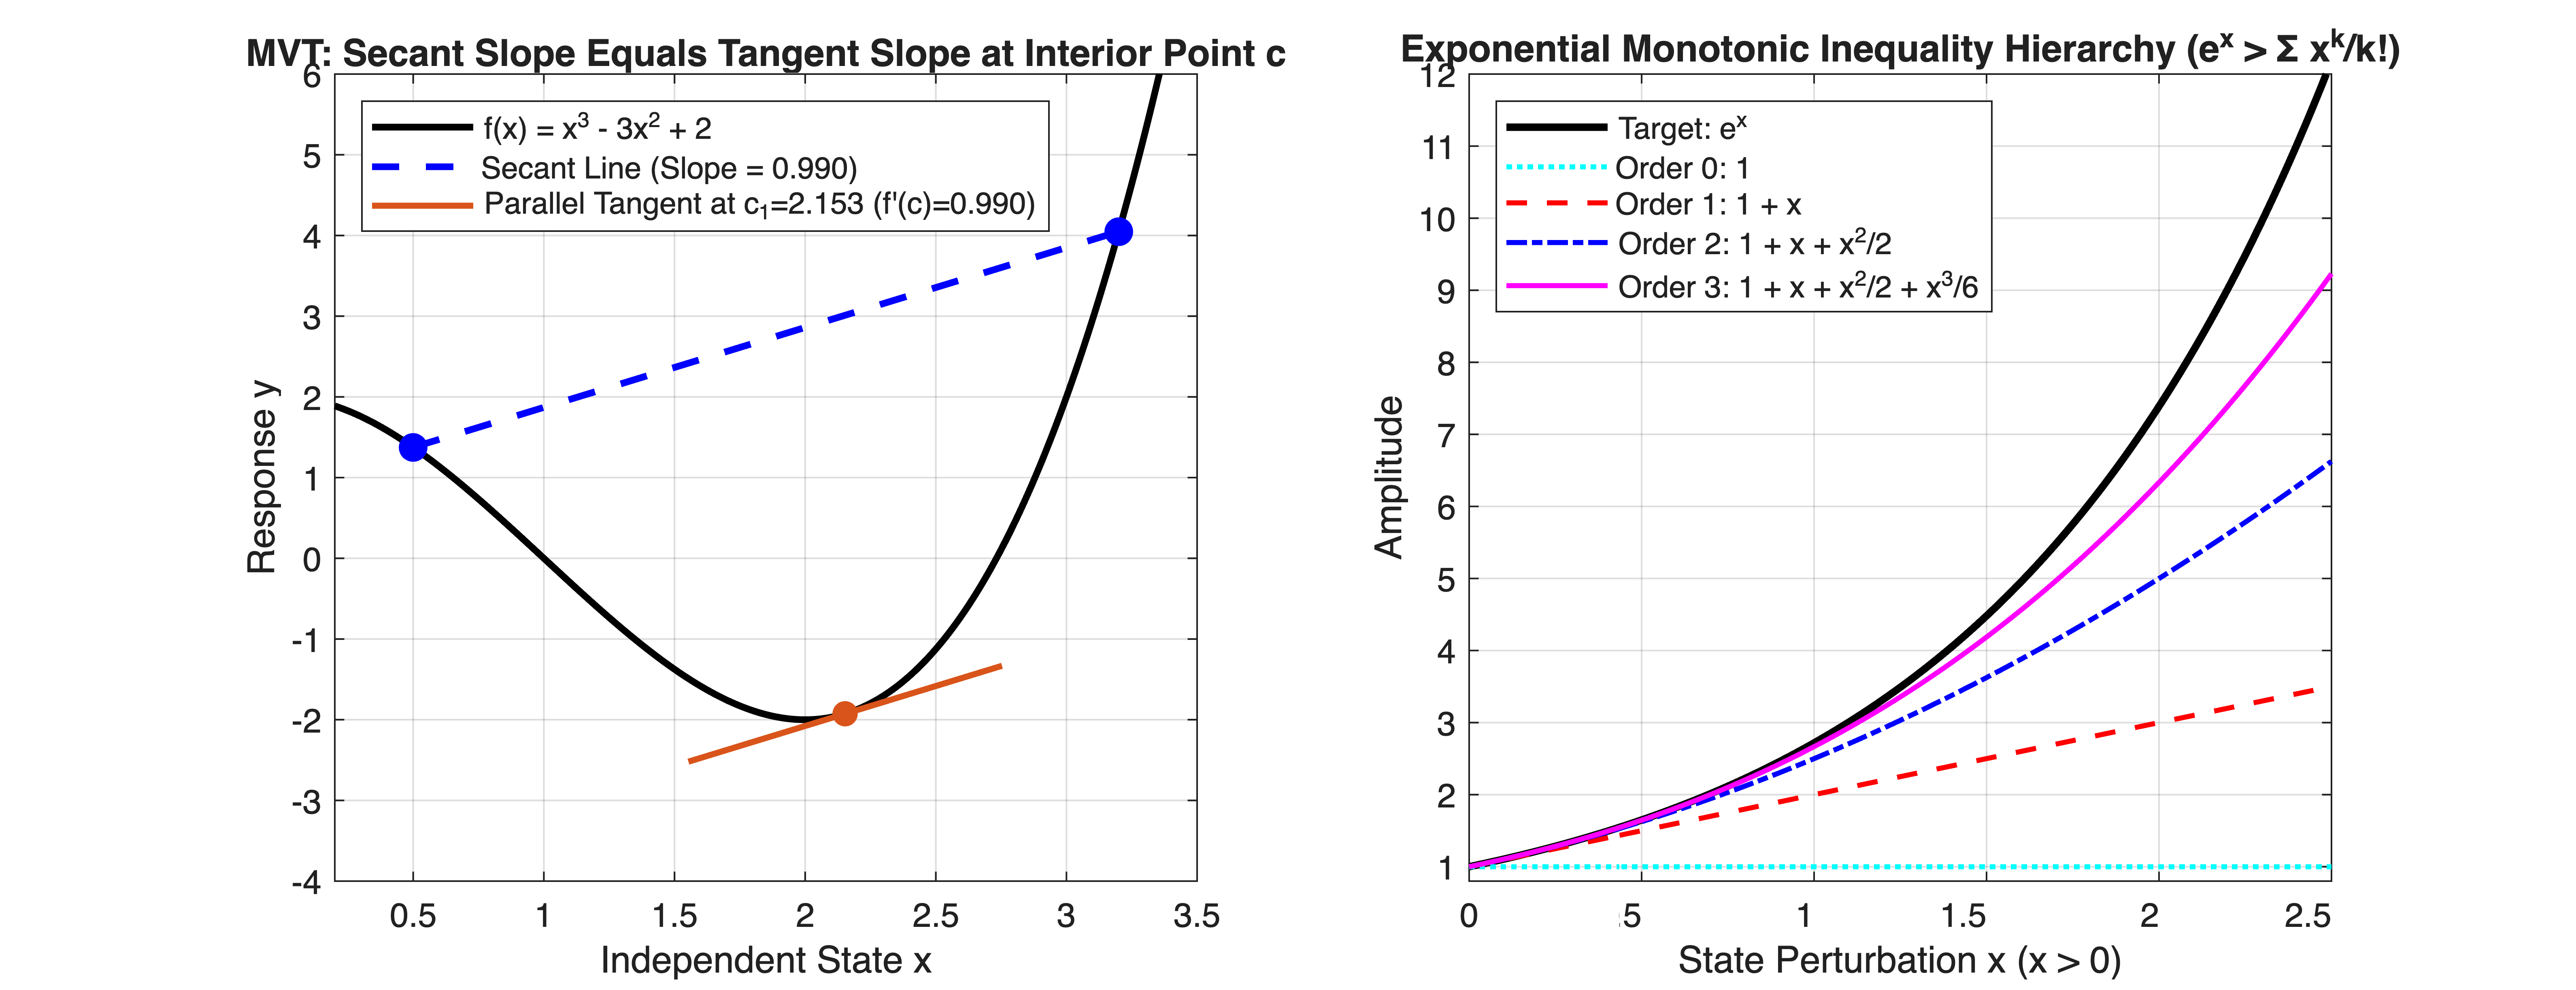

In [1]:
%% MIT 18.01 Lecture 14: Mean Value Theorem & Inequality Bounds Simulation
% Mathematical Tool Application: Used for bounding state estimation errors via
% Lipschitz continuity, proving monotonic decay of Lyapunov candidate functions,
% and formulating truncation error bounds for adaptive ODE step-size solvers.


clear; clc; close all;


%% Part 1: Mean Value Theorem Geometric Validation & Singularity Contrast
% Smooth differentiable test function: f(x) = x^3 - 3*x^2 + 2 on [a, b] = [0.5, 3.2]
f_poly = @(x) x.^3 - 3*x.^2 + 2;
df_poly = @(x) 3*x.^2 - 6*x;


a = 0.5;
b = 3.2;
m_secant = (f_poly(b) - f_poly(a)) / (b - a);


% Solve for intermediate points c in (a, b) where f'(c) = m_secant
% 3*c^2 - 6*c - m_secant = 0
roots_c = roots([3, -6, -m_secant]);
valid_c = roots_c(roots_c > a & roots_c < b);


x_domain = linspace(0.2, 3.5, 400);


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
plot(x_domain, f_poly(x_domain), 'k-', 'LineWidth', 2.0, 'DisplayName', 'f(x) = x^3 - 3x^2 + 2'); hold on;


% Plot secant line connecting (a, f(a)) and (b, f(b))
plot([a, b], [f_poly(a), f_poly(b)], 'b--', 'LineWidth', 2.0, ...
    'DisplayName', sprintf('Secant Line (Slope = %.3f)', m_secant));
plot([a, b], [f_poly(a), f_poly(b)], 'bo', 'MarkerSize', 8, 'MarkerFaceColor', 'b', 'HandleVisibility', 'off');


% Plot parallel tangent lines at all valid c locations
colors = [0.85, 0.33, 0.1; 0.49, 0.18, 0.56];
for k = 1:length(valid_c)
    c_val = valid_c(k);
    y_c = f_poly(c_val);
    x_tan = linspace(c_val - 0.6, c_val + 0.6, 50);
    y_tan = y_c + m_secant * (x_tan - c_val);
    plot(x_tan, y_tan, '-', 'Color', colors(k, :), 'LineWidth', 1.8, ...
        'DisplayName', sprintf('Parallel Tangent at c_{%d}=%.3f (f''(c)=%.3f)', k, c_val, df_poly(c_val)));
    plot(c_val, y_c, 'o', 'MarkerSize', 7, 'MarkerFaceColor', colors(k, :), 'Color', colors(k, :), 'HandleVisibility', 'off');
end


grid on;
xlim([0.2, 3.5]); ylim([-4, 6]);
xlabel('Independent State x');
ylabel('Response y');
title('MVT: Secant Slope Equals Tangent Slope at Interior Point c');
legend('Location', 'northwest');


%% Part 2: Successive Taylor Inequality Chain (e^x Bounds for x > 0)
subplot(1, 2, 2);
x_pos = linspace(0, 2.5, 300);
y_exp = exp(x_pos);


% Successive lower bounds derived via f' > 0 monotonicity
P0 = ones(size(x_pos));
P1 = 1 + x_pos;
P2 = 1 + x_pos + (x_pos.^2)/2;
P3 = 1 + x_pos + (x_pos.^2)/2 + (x_pos.^3)/6;


plot(x_pos, y_exp, 'k-', 'LineWidth', 2.2, 'DisplayName', 'Target: e^x'); hold on;
plot(x_pos, P0, 'c:',  'LineWidth', 1.5, 'DisplayName', 'Order 0: 1');
plot(x_pos, P1, 'r--', 'LineWidth', 1.5, 'DisplayName', 'Order 1: 1 + x');
plot(x_pos, P2, 'b-.', 'LineWidth', 1.5, 'DisplayName', 'Order 2: 1 + x + x^2/2');
plot(x_pos, P3, 'm-',  'LineWidth', 1.5, 'DisplayName', 'Order 3: 1 + x + x^2/2 + x^3/6');


grid on;
xlim([0, 2.5]); ylim([0.8, 12]);
xlabel('State Perturbation x (x > 0)');
ylabel('Amplitude');
title('Exponential Monotonic Inequality Hierarchy (e^x > \Sigma x^k/k!)');
legend('Location', 'northwest');